## Part A — the supervised setup

## TASK 01 Split and scale

In [1]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Load the CSV file
df = pd.read_csv("california_housing.csv")  # Replace with your actual CSV filename

# 2. Separate features (X) and target (y)
X = df[[
    "MedInc",
    "HouseAge",
    "AveRooms",
    "AveBedrms",
    "Population",
    "AveOccup",
    "Latitude",
    "Longitude"
]]

y = df["MedHouseVal"]

# 3. Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42 )

# 4. Standardize features
scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

# 5. Check the results
print("Training features shape:", X_train_scaled.shape)
print("Testing features shape:", X_test_scaled.shape)

print("\nMean of scaled training features:")
print(pd.DataFrame(X_train_scaled, columns=X.columns).mean().round(3))

print("\nStandard deviation of scaled training features:")
print(pd.DataFrame(X_train_scaled, columns=X.columns).std(ddof=0).round(3))

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


Training features shape: (4000, 8)
Testing features shape: (1000, 8)

Mean of scaled training features:
MedInc       -0.0
HouseAge      0.0
AveRooms      0.0
AveBedrms     0.0
Population    0.0
AveOccup     -0.0
Latitude     -0.0
Longitude    -0.0
dtype: float64

Standard deviation of scaled training features:
MedInc        1.0
HouseAge      1.0
AveRooms      1.0
AveBedrms     1.0
Population    1.0
AveOccup      1.0
Latitude      1.0
Longitude     1.0
dtype: float64

Training target shape: (4000,)
Testing target shape: (1000,)


1\. Why hold back a test set instead of training on everything? 

To evaluate how well the model predicts unseen data and detect overfitting.

2\. What goes wrong if you fit the scaler on the full dataset before splitting? 

It causes data leakage because the scaler uses information from the test set, making the evaluation less reliable.

3\. Why does gradient descent care about feature scaling but the closed-form solution doesn't? 

Gradient descent can converge slowly or struggle when features have very different scales, while the closed-form solution for linear regression calculates coefficients directly and is less sensitive to feature scaling (though scaling can still improve numerical stability).

## Part B — implement it three ways (the deliverable)

## TASK 02 Method 1 — the closed-form solution

In [2]:

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

# 1. Load the California Housing dataset
df = pd.read_csv("california_housing.csv")

# 2. Separate features (X) and target (y)
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

# 3. Split the dataset (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Add a bias column of 1s
def add_bias(X):
    return np.c_[np.ones(len(X)), X]

Xtr = add_bias(X_train_scaled)
Xte = add_bias(X_test_scaled)

# 6. Implement the normal equation
w = np.linalg.inv(Xtr.T @ Xtr) @ Xtr.T @ y_train.values

# 7. Print the learned weights
feature_names = ["Bias"] + list(X.columns)

print("Learned weights:")
for name, weight in zip(feature_names, w):
    print(f"{name}: {weight:.6f}")

# 8. Predict on the test set
pred = Xte @ w

# 9. Calculate test Mean Squared Error (MSE)
mse = mean_squared_error(y_test, pred)

print("\nTest MSE:", round(mse, 6))


Learned weights:
Bias: 2.209491
MedInc: 0.879916
HouseAge: 0.169620
AveRooms: 0.033981
AveBedrms: 0.001896
Population: -0.002174
AveOccup: -0.112161
Latitude: -0.149141
Longitude: -0.170009

Test MSE: 0.164769


1\. What does \\((X^T X)^{-1}\\) actually do here?

 It calculates the inverse of \\(X^T X\\), allowing us to solve directly for the weights that minimize the sum of squared prediction errors, provided the inverse exists.

2\. Why is this called a “closed-form” solution? 

Because it calculates the optimal weights directly using a mathematical formula, without repeatedly updating them through iterations.

3\. When might the closed-form solution fail or be impractical?

 It can fail when \\(X^T X\\) is singular, such as when features are redundant, and become computationally expensive with very many features because matrix inversion requires substantial time and memory.

## TASK 03 Method 2 — gradient descent

Gradient Descent Weights:
Bias: 2.209491
MedInc: 0.879916
HouseAge: 0.169620
AveRooms: 0.033981
AveBedrms: 0.001896
Population: -0.002174
AveOccup: -0.112161
Latitude: -0.149141
Longitude: -0.170009

Initial training MSE: 5.8847
Final training MSE: 0.158804


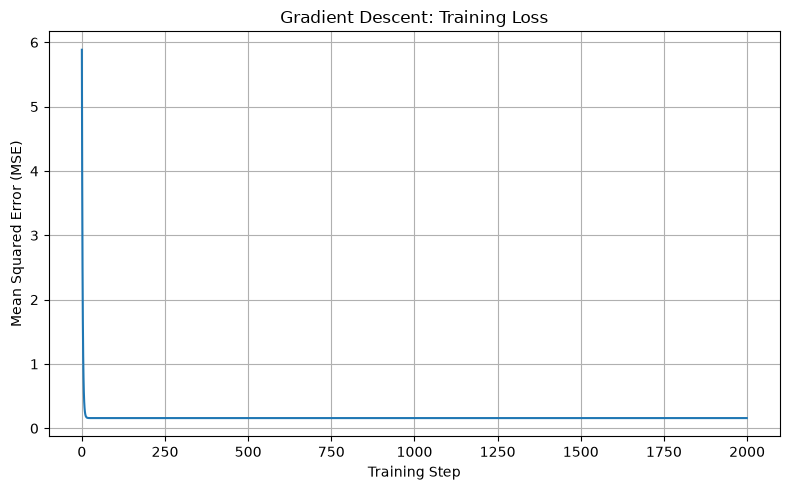


Closed-Form Weights:
Bias: 2.209491
MedInc: 0.879916
HouseAge: 0.169620
AveRooms: 0.033981
AveBedrms: 0.001896
Population: -0.002174
AveOccup: -0.112161
Latitude: -0.149141
Longitude: -0.170009

Weight Comparison:
Maximum absolute weight difference: 4.440892098500626e-16
Weights approximately match: True

Gradient Descent Test MSE: 0.164769


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

# 1. Load the California Housing CSV file
df = pd.read_csv("california_housing.csv")

# 2. Separate features and target
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

# 3. Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Scale features using training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Add a bias column of ones
def add_bias(X):
    return np.c_[np.ones(len(X)), X]

Xtr = add_bias(X_train_scaled)
Xte = add_bias(X_test_scaled)

y_train_np = y_train.to_numpy()
y_test_np = y_test.to_numpy()

# 6. Gradient descent from scratch
w_gd = np.zeros(Xtr.shape[1])  # Start with zero weights
lr = 0.1
steps = 2000
loss_history = []

for step in range(steps):
    # Calculate predictions
    pred_train = Xtr @ w_gd

    # Calculate training MSE
    loss = np.mean((pred_train - y_train_np) ** 2)
    loss_history.append(loss)

    # Calculate gradient of MSE
    grad = (2 / len(y_train_np)) * Xtr.T @ (
        pred_train - y_train_np
    )

    # Update weights
    w_gd -= lr * grad

# 7. Print gradient-descent weights
feature_names = ["Bias"] + list(X.columns)

print("Gradient Descent Weights:")
for name, weight in zip(feature_names, w_gd):
    print(f"{name}: {weight:.6f}")

print("\nInitial training MSE:", round(loss_history[0], 6))
print("Final training MSE:", round(loss_history[-1], 6))

# 8. Plot training loss
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Training Step")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Gradient Descent: Training Loss")
plt.grid(True)
plt.tight_layout()
plt.show()

# 9. Calculate closed-form weights for comparison
w_closed = np.linalg.pinv(Xtr) @ y_train_np

print("\nClosed-Form Weights:")
for name, weight in zip(feature_names, w_closed):
    print(f"{name}: {weight:.6f}")

# 10. Compare the two sets of weights
print("\nWeight Comparison:")
print("Maximum absolute weight difference:",
    np.max(np.abs(w_gd - w_closed)))

print("Weights approximately match:",
    np.allclose(w_gd, w_closed, atol=1e-3))

# 11. Evaluate gradient-descent model on test data
pred_test = Xte @ w_gd
test_mse = mean_squared_error(y_test_np, pred_test)

print("\nGradient Descent Test MSE:", round(test_mse, 6))



1\. Learning rate too high vs. too low: 

Too high → the loss curve may jump around or diverge. 

Too low → the loss decreases very slowly.

2\. Why should both methods reach the same answer? 

Both minimize the same Mean Squared Error (MSE) objective for linear regression. With a suitable learning rate and enough iterations, Gradient Descent should approach the closed-form solution.

3\. Why is Gradient Descent more important overall? 

It scales better to very large datasets and complex models, such as neural networks, where a closed-form solution is usually unavailable or impractical.

## TASK 04 Method 3 — sklearn, and prove all three match

In [4]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

# 1. Fit sklearn Linear Regression on the same scaled training data
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# 2. Get sklearn intercept and coefficients
sklearn_weights = np.r_[model.intercept_, model.coef_]

print("Sklearn Intercept:", model.intercept_)
print("Sklearn Coefficients:", model.coef_)

# 3. Create feature names, including the bias
feature_names = ["Bias"] + list(X.columns)

# 4. Put all three sets of weights side by side
comparison = pd.DataFrame({
    "Feature": feature_names,
    "Closed-Form": w_closed,
    "Gradient Descent": w_gd,
    "Sklearn": sklearn_weights
})

print("\nComparison of Weights:")
print(comparison.round(6).to_string(index=False))

# 5. Check whether all three methods agree
print("\nClosed-Form vs Sklearn:",
    np.allclose(w_closed, sklearn_weights, atol=1e-3))

print("Gradient Descent vs Sklearn:",
    np.allclose(w_gd, sklearn_weights, atol=1e-3))

print("Closed-Form vs Gradient Descent:",
    np.allclose(w_closed, w_gd, atol=1e-3))

# 6. Show the maximum differences
print("\nMaximum absolute differences:")
print("Closed-Form vs Sklearn:",
    np.max(np.abs(w_closed - sklearn_weights)))

print("Gradient Descent vs Sklearn:",
    np.max(np.abs(w_gd - sklearn_weights)))

Sklearn Intercept: 2.209490875
Sklearn Coefficients: [ 0.87991553  0.16961959  0.03398139  0.00189607 -0.00217351 -0.11216059
 -0.14914137 -0.17000858]

Comparison of Weights:
   Feature  Closed-Form  Gradient Descent   Sklearn
      Bias     2.209491          2.209491  2.209491
    MedInc     0.879916          0.879916  0.879916
  HouseAge     0.169620          0.169620  0.169620
  AveRooms     0.033981          0.033981  0.033981
 AveBedrms     0.001896          0.001896  0.001896
Population    -0.002174         -0.002174 -0.002174
  AveOccup    -0.112161         -0.112161 -0.112161
  Latitude    -0.149141         -0.149141 -0.149141
 Longitude    -0.170009         -0.170009 -0.170009

Closed-Form vs Sklearn: True
Gradient Descent vs Sklearn: True
Closed-Form vs Gradient Descent: True

Maximum absolute differences:
Closed-Form vs Sklearn: 1.4432899320127035e-15
Gradient Descent vs Sklearn: 1.7763568394002505e-15


1\. Why learn from-scratch versions?

 They help us understand the mathematics behind the model, how weights are learned, and how errors are minimized.

2\. What is the “create, fit, predict” pattern?

- `create`: initialize the model, e.g. `LinearRegression()`.
- `fit`: train it using data, e.g. `model.fit(X_train, y_train)`.
- `predict`: make predictions, e.g. `model.predict(X_test)`.

&#x20;  Sklearn uses this consistent pattern across many models, making them easier to learn and use.

3\. Does sklearn use Closed-Form or Gradient Descent internally?

 For ordinary `LinearRegression` with dense data, sklearn uses a least-squares solver (`scipy.linalg.lstsq`), not Gradient Descent. It solves the least-squares problem numerically, using a method based on singular value decomposition (SVD).&#x20;




## Part C — measure and interpret

## TASK 05 Evaluate with four metrics

MSE: 0.1648
RMSE: 0.4059
MAE: 0.3193
R² Score: 0.8383

RMSE in dollars: $ 40591.77
MAE in dollars: $ 31932.1


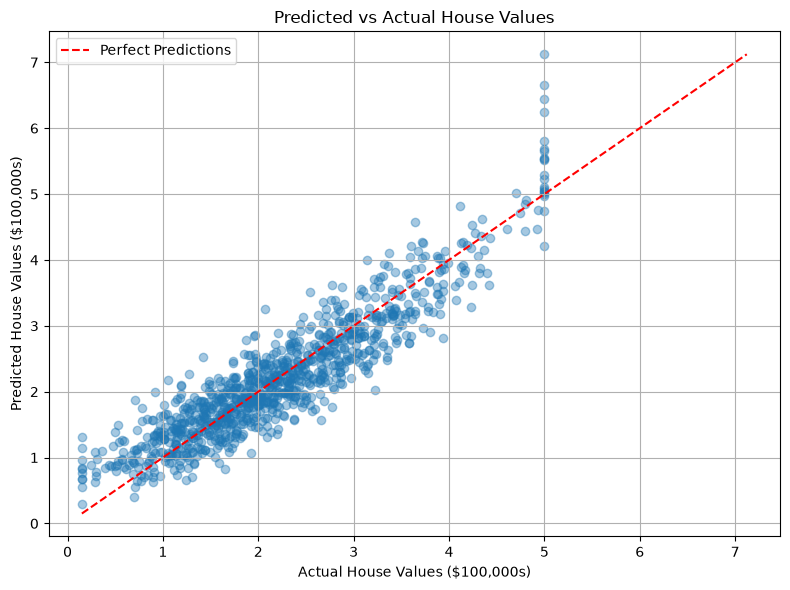

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# 1. Predict house values on the test set
pred = model.predict(X_test_scaled)

# 2. Calculate evaluation metrics
mse = mean_squared_error(y_test, pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, pred)
r2 = r2_score(y_test, pred)

# 3. Print the results
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("MAE:", round(mae, 4))
print("R² Score:", round(r2, 4))

# 4. Convert RMSE and MAE to dollars
# MedHouseVal is measured in units of $100,000
print("\nRMSE in dollars: $", round(rmse * 100000, 2))
print("MAE in dollars: $", round(mae * 100000, 2))

# 5. Predicted vs Actual scatter plot
lims = [
    min(y_test.min(), pred.min()),
    max(y_test.max(), pred.max())
]

plt.figure(figsize=(8, 6))
plt.scatter(y_test, pred, alpha=0.4)
plt.plot(lims, lims, "r--", label="Perfect Predictions")
plt.xlabel("Actual House Values ($100,000s)")
plt.ylabel("Predicted House Values ($100,000s)")
plt.title("Predicted vs Actual House Values")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

1\. Why report both RMSE and MAE? 

MAE gives the average absolute prediction error, while RMSE penalizes large errors more heavily.

2\. What do R² values mean?

- R² = 0: The model performs no better than predicting the average target value, in terms of squared error.
- Negative R²: The model performs worse than predicting the average target value.

3\. Is a $40,000 typical error good or bad?

 It depends on typical house prices, the cost of prediction errors, the model's intended use, and how its error compares with other models.

## TASK 06 Interpret the coefficients (the other deliverable)

Feature weights sorted by absolute size:
   feature    weight
    MedInc  0.879916
 Longitude -0.170009
  HouseAge  0.169620
  Latitude -0.149141
  AveOccup -0.112161
  AveRooms  0.033981
Population -0.002174
 AveBedrms  0.001896


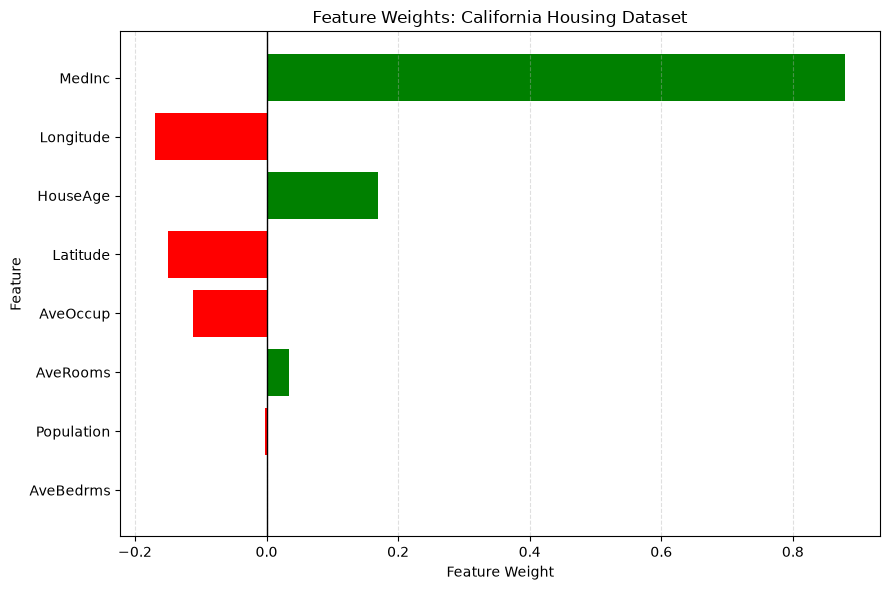


Features with near-zero weights:
   feature    weight
Population -0.002174
 AveBedrms  0.001896


In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Create a DataFrame of feature names and weights
coefs = pd.DataFrame({
    "feature": X.columns,
    "weight": model.coef_
})

# 2. Sort by absolute weight, largest effect first
coefs = coefs.reindex(
    coefs["weight"].abs().sort_values(ascending=False).index
)

print("Feature weights sorted by absolute size:")
print(coefs.to_string(index=False))

# 3. Assign colours: green for positive, red for negative
colors = [
    "green" if weight > 0 else "red"
    for weight in coefs["weight"]
]

# 4. Create a horizontal bar chart
plt.figure(figsize=(9, 6))
plt.barh(coefs["feature"], coefs["weight"], color=colors)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Feature Weight")
plt.ylabel("Feature")
plt.title("Feature Weights: California Housing Dataset")
plt.gca().invert_yaxis()
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# 5. Identify features with near-zero weights
threshold = 0.01
near_zero = coefs[coefs["weight"].abs() < threshold]

print("\nFeatures with near-zero weights:")
if near_zero.empty:
    print("None below the threshold of", threshold)
else:
    print(near_zero.to_string(index=False))

1\. Why does scaling make coefficients comparable? 

 puts features on a similar scale, so their coefficients reflect the effect of a one-standard-deviation change rather than differences in measurement units.

2\. What do positive and negative weights mean?

- Positive weight: As the feature increases, the predicted house value tends to increase, holding other features constant.
- Negative weight: As the feature increases, the predicted house value tends to decrease, holding other features constant.

3\. Where is explainability important?

 In loan approvals, medicine, and hiring, explanations help people understand decisions, detect bias, and ensure accountability.